# Wektory tematyczne
- Wektory TF-IDF liczą wyłącznie słowa o tej samej 
pisowni
- Wyzwania językowe:
    - homonimy (ta sama pisownia i wymowa, różne 
znaczenia, np. zamek)
    - zeugma (dwa znaczenia w jednym zdaniu, np. 
uporządkował myśli i sztućce)
    - homografy (ta sama pisownia, różna 
wymowa i znaczenie, np. rozmarzać)
    - homofony (ta sama wymowa, różna 
pisownia i znaczenie, np. może i morze)


- Wektory tematyczne są wektorami gęstymi o stosunkowo niewielkiej liczbie elementów
- Pozycja wektora odpowiada tematowi
- Przypisanie słów do tematów odbywa się automatycznie 
- Technika LSA (Latent semantic analysis – utajona analiza 
semantyczna) przypisuje słowa do tematów korzystając z 
algorytmu SVD (singular value decomposition – rozkład wg 
wartości osobliwych)

# Model tematyczny

- Modelem tematycznym jest (statystycznym) modelem odkrywania tematów w zbiorze dokumentów;
- Tematy stanowią wymiary wektorów tematycznych;
- Za pomocą wektorów tematycznych można przedstawiać:
    - słowa (wektor słowo-temat);
    - dokumenty (wektor dokument-temat).

In [3]:
import pandas as pd
import numpy as np

Funkcje wykorzystane w dalszej części do pokazywania macierzy DTM, TDM, U, $\Sigma$ i $V^T$ 

In [4]:
def show_DTM(cv, DTM):
    tokens = sorted([k for k in cv.vocabulary_.keys()])
    df = pd.DataFrame(DTM, columns=tokens,
                      index=[f'doc{i}' for i in range(DTM.shape[0])])
    return df

In [5]:
def show_TDM(cv, TDM):
    tokens = sorted([k for k in cv.vocabulary_.keys()])
    df = pd.DataFrame(TDM, index=tokens,
                      columns=[f'doc{i}' for i in range(TDM.shape[1])])
    return df

In [6]:
def show_U(U, cv, n_terms):
    #rows = tf_as_df.loc['token',:]
    rows = sorted([k for k in cv.vocabulary_.keys()])
    columns = [f'topic{i}' for i in range(n_terms)]
    return(pd.DataFrame(U, index=rows, columns=columns))

In [7]:
def show_Sigma(S, n_terms, n_docs):
    S = np.hstack((np.diag(S),np.zeros((n_terms,n_docs-n_terms))))
    rows = [f'{i}' for i in range(n_terms)]
    columns = [f'{i}' for i in range(n_docs)]
    return(pd.DataFrame(S, index=rows, columns=columns))

In [8]:
def show_VT(VT, n_docs):
    rows = [f'{i}' for i in range(n_docs)]
    columns = [f'{i}' for i in range(n_docs)]
    return(pd.DataFrame(VT, index=rows, columns=columns))

# Singular value decomposition (SVD) - rozkład wartości osobliwych

Do utworzenia tematów wykorzystamy rozkład wartości osobliwych.
- Zakładamy, że dowolna macierze rzeczywista M może zostać przedstawiona w postaci Rozkładu SVD:

$M$ = $U$ $\Sigma$ $V^T$

gdzie:
- $U$ oraz $V$ są macierzami ortagolnymi;
- $\Sigma$ jest macierzą diagonalną.

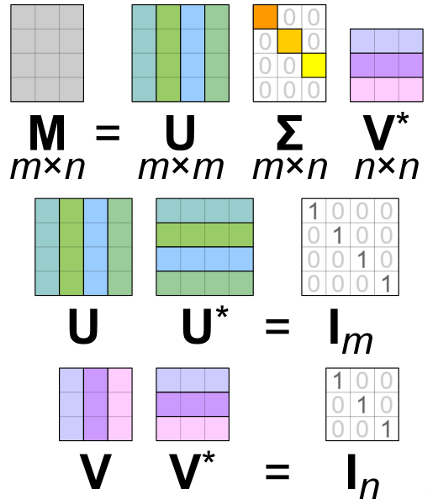


- W przykładzie użycia rozkładaną macierzą będzie macierz słowo-dokument;
- Ograniczymy się do słownika składającego się z 6 wyrazów:

In [9]:
vocabulary = {'fly':0, 'sea':1, 'food':2, 
              'birds':3, 'boats':4, 'planes':5}
n_terms = len(vocabulary) # 6

- Korpus będzie składał się z 10 bardzo prostych dokumentów:

In [10]:
corpus = ['Birds fly over the sea',
          'People eat food by the sea',
          'Waves crash as birds fly high',
          'Fish is the best food near the sea',
          'Planes fly while the sea sparkles below',
          'Food tastes better with the sea breeze',
          'Birds fly low to find food',
          'The sea is calm while boats bring food',
          'Clouds drift as waves and birds fly',
          'Fresh food is served near the sea'
         ]

n_docs = len(corpus) # 10

- Macierz słowo-dokument (term-document matrix, TDM) możemy utworzyć korzystając z CountVectorizer (który zwraca macierz dokument-słowo, DTM, zatem wynik należy transponować - .T):

In [11]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(vocabulary=vocabulary)
DTM = cv.fit_transform(corpus).todense()
TDM = DTM.T

In [12]:
show_DTM(cv, DTM)

,birds,boats,fly,food,planes,sea
doc0,1,1,0,1,0,0
doc1,0,1,1,0,0,0
doc2,1,0,0,1,0,0
doc3,0,1,1,0,0,0
doc4,1,1,0,0,0,1
doc5,0,1,1,0,0,0
doc6,1,0,1,1,0,0
doc7,0,1,1,0,1,0
doc8,1,0,0,1,0,0
doc9,0,1,1,0,0,0


In [13]:
show_TDM(cv, TDM)

,doc0,doc1,doc2,doc3,doc4,doc5,doc6,doc7,doc8,doc9
birds,1,0,1,0,1,0,1,0,1,0
boats,1,1,0,1,1,1,0,1,0,1
fly,0,1,0,1,0,1,1,1,0,1
food,1,0,1,0,0,0,1,0,1,0
planes,0,0,0,0,0,0,0,1,0,0
sea,0,0,0,0,1,0,0,0,0,0


Rozkład macierzy TDM można wykonać korzystając z metody SVD modułu NumPy:

In [14]:
import numpy as np

In [15]:
U, sigma, VT = np.linalg.svd(TDM)

Macierz $U$ zawiera odnalezione tematy (wartość zaokrąglona do 2. miejca po przecinku):

In [16]:
show_U(U, cv, n_terms).round(2)

,topic0,topic1,topic2,topic3,topic4,topic5
birds,0.38,0.64,-0.19,0.00,-0.28,-0.58
boats,0.65,-0.31,-0.47,0.01,0.50,0.00
fly,0.56,-0.37,0.55,-0.21,-0.45,-0.00
food,0.30,0.59,0.37,0.06,0.31,0.58
planes,0.10,-0.11,0.07,0.98,-0.15,-0.00
sea,0.09,0.05,-0.55,-0.06,-0.59,0.58


- Macierz $\Sigma$ zawiera istotność poszczególnych tematów;
- Metoda SVD zwraca jedynie wartości z przekątnej macierzy $\Sigma$ uporządkowane nierosnąco:

In [17]:
sigma.round(2)

array([3.63, 2.68, 1.48, 0.89, 0.79, 0.  ])

Macierz $\Sigma$:

In [18]:
show_Sigma(sigma, n_terms, n_docs).round(2)

,0,1,2,3,4,5,6,7,8,9
0,3.63,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0
1,0.00,2.68,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0
2,0.00,0.00,1.48,0.00,0.00,0.0,0.0,0.0,0.0,0.0
3,0.00,0.00,0.00,0.89,0.00,0.0,0.0,0.0,0.0,0.0
4,0.00,0.00,0.00,0.00,0.79,0.0,0.0,0.0,0.0,0.0
5,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0


Macierz $V^T$ (wartości zaokrąglone do 2. miejsca po przecinku):

In [19]:
show_VT(VT, n_docs).round(2)

,0,1,2,3,4,5,6,7,8,9
0,0.37,0.34,0.19,0.34,0.31,0.34,0.34,0.36,0.19,0.34
1,0.34,-0.26,0.46,-0.26,0.14,-0.26,0.32,-0.30,0.46,-0.26
2,-0.20,0.05,0.12,0.05,-0.82,0.05,0.49,0.10,0.12,0.05
3,0.08,-0.22,0.07,-0.22,-0.05,-0.22,-0.16,0.87,0.07,-0.22
4,0.69,0.07,0.04,0.07,-0.46,0.07,-0.53,-0.12,0.04,0.07
5,-0.30,-0.59,0.21,0.20,0.00,0.34,-0.30,-0.00,0.38,0.34
6,0.20,-0.43,-0.21,0.73,0.00,-0.30,0.20,-0.00,-0.18,-0.20
7,-0.25,0.27,0.74,0.30,0.00,-0.33,-0.25,0.00,-0.25,-0.00
8,-0.20,0.38,-0.30,0.24,-0.00,-0.38,-0.20,0.00,0.70,-0.05
9,0.09,-0.13,-0.09,-0.19,-0.00,-0.56,0.09,-0.00,-0.10,0.78


Oznaczając $N$ - liczba dokumentów w korpusie;

$M$ - liczba termów (tokenów) oraz $P$ - liczba tematów, wymiary macierzy to:
- $U _{MxP}$;
- $\Sigma _{PxP}$;
- $V _{PxN}$;

Odtworzenie oryginalnej macierzy TDM wyliczając  $U$ $\Sigma$ $V^T$:

- W podanym przykładzie macierz $U$ jest kwadratowa, zatem liczba tematów jest taka sama, jak liczba tokenów w słowniku;
- Każdy temat (kolumna) jest wyrażona jako związek słów, np: "topic0" to 0,38x "birds" + 0,65x "boats" + 0,56x "fly" + 0,3x "food" + 0,1x "planes" +0,09x "sea".

Interpretacja takiego tematu:
- Każde słowo (wiersz) to wektor słowo-temat;
- Redukcja liczby kolumn pozwala opisać słowo za pomocą mniejszej liczby tematów;
- Ceną jest utrata informacji.

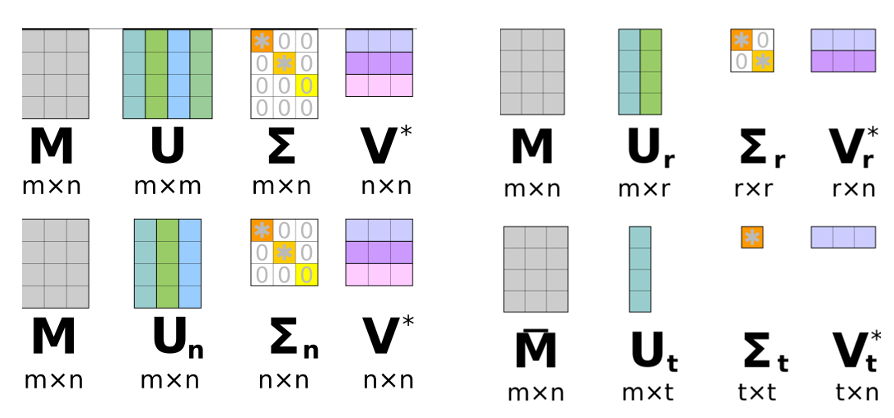

Odtworzenie oryginalnej macierzy TDM, przy czym najpierw konieczne jest utworzenie macierzy $\Sigma$ z wektora `sigma`:

In [20]:
Sigma = np.hstack((np.diag(sigma), 
                   # uzupełnienie zerami 
                   np.zeros((n_terms,n_docs-n_terms))))
# odtworzenie macierzy
pd.DataFrame(U @ Sigma @ VT).round(2)

,0,1,2,3,4,5,6,7,8,9
0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,1.0,1.0,-0.0,1.0,1.0,1.0,-0.0,1.0,-0.0,1.0
2,0.0,1.0,-0.0,1.0,0.0,1.0,1.0,1.0,-0.0,1.0
3,1.0,0.0,1.0,0.0,-0.0,0.0,1.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,1.0,-0.0,0.0
5,-0.0,0.0,-0.0,0.0,1.0,0.0,-0.0,0.0,-0.0,0.0


Wyliczenie błędy przy odtworzeniu TDM (z reprezentacji przez wektor BoW) w zależności od liczbt usuniętych tematów:

In [21]:
error = [0]
S = Sigma
for numdim in range(len(S), 0, -1):
    S[numdim-1, numdim-1] = 0
    reconstructed_TDM = U @ S @ VT
    error.append(np.sqrt(np.power((reconstructed_TDM - TDM).flatten(), 2).sum()/np.prod(TDM.shape)))
error_bow = np.array(error).round(2)

Wyliczanie błędu przy odtwarzaniu TDM (z reprezentacji TFIDF) w zależności od liczby usuniętych tematów:

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

# utworzenie reprezentacji TFIDF
tv = TfidfVectorizer(vocabulary=vocabulary)
DTM = tv.fit_transform(corpus).todense()
TDM = DTM.T

# SVD
U, sigma, VT = np.linalg.svd(TDM)
Sigma = np.hstack((np.diag(sigma), # uzupełnienie zerami
                   np.zeros((n_terms,n_docs-n_terms))))

# wyliczenie błędu
error = [0]
S = Sigma
for numdim in range(len(S),0,-1):
    S[numdim-1, numdim-1] = 0
    reconstructed_TDM = U @ S @ VT
    error.append(np.sqrt(np.power((reconstructed_TDM - TDM).flatten(),2).sum()/np.prod(TDM.shape)))
error_tfidf = np.array(error).round(2)

Wykres błędu:

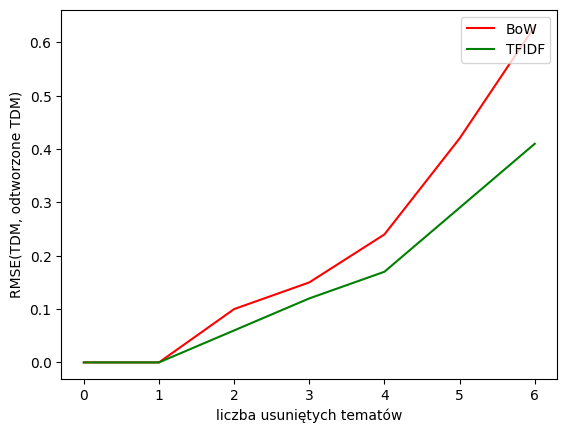

In [23]:
import matplotlib.pyplot as plt

# punkty obu klas
plt.plot(list(range(n_terms+1)), error_bow, color='r', label='BoW')
plt.plot(list(range(n_terms+1)), error_tfidf, color='g', label='TFIDF')

plt.xlabel('liczba usuniętych tematów')
plt.ylabel('RMSE(TDM, odtworzone TDM)')
plt.legend(loc='upper right')
plt.show()

# Wektory Tematyczne

- stosowanie wektorów tematycznych, takich jak powyższe wektory tematyczne w praktyce często prznyosi lepsze rezultaty, niż stosowanie wektorów rzadkich (BoW, TFIDF);
- Krótsze wektory łatwiej wykorzystywać jako cechy w uczeniu maszynowym;
- Wektory takie lepiej uogólniają, niż liczby wystąpień słów;
- Mogą wyłapywać synonimy.

Wykorzystamy wektory tematycze do zadania klasyfikacji wiadomości ze zbioru [20 Newsgroups](https://www.kaggle.com/datasets/crawford/20-newsgroups)

In [24]:
from sklearn.datasets import fetch_20newsgroups

X_train, y_train = fetch_20newsgroups(subset='train', 
                                                 return_X_y=True, 
                                                 remove=('headers', 'footers', 'quotes'))
X_test, y_test = fetch_20newsgroups(subset='test', 
                                               return_X_y=True, 
                                               remove=('headers', 'footers', 'quotes'))

Utworzenie wektorów TFIDF:

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer

tv = TfidfVectorizer(use_idf=True, norm=None)
X_train = tv.fit_transform(X_train)
X_test = tv.transform(X_test)

Klasyfikacja za pomocą naiwnego klasyfikatora Bayesa:

In [26]:
from sklearn.naive_bayes import MultinomialNB

clf = MultinomialNB()
clf.fit(X_train, y_train)
print(f'Dokładność = {clf.score(X_test, y_test):0.2}')

Dokładność = 0.66


Ponowne podzielenie danych:

In [27]:
from sklearn.datasets import fetch_20newsgroups

X_train, y_train = fetch_20newsgroups(subset='train', 
                                                 return_X_y=True, 
                                                 remove=('headers', 'footers', 'quotes'))
X_test, y_test = fetch_20newsgroups(subset='test', 
                                               return_X_y=True, 
                                               remove=('headers', 'footers', 'quotes'))

Utworzenie wektorów TFIDF:

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

tv = TfidfVectorizer(use_idf=True, norm=None)
X_train = tv.fit_transform(X_train)
X_test = tv.transform(X_test)

# Rozmiar wektora TFIDF
X_train[0, :].shape

(1, 101631)

Reprezentacja 500-wymiarowa znaleziona za pomocą algorytmu PCA,

normalizacja (L2) wejściowego wektora TFIDF zwiększa efektywność:

In [29]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

X_train = normalize(X_train)
X_test = normalize(X_test)

pca = PCA(n_components=500)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

# rozmiar wektora tematycznego
X_train[0,:].shape

(500,)

PCA wymaga macierzy gęstej, dla TFIDF standardowo używa się `TruncatedSVD`:

In [30]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

X_train = normalize(X_train)
X_test = normalize(X_test)

svd = TruncatedSVD(n_components=500, random_state=42)

X_train = svd.fit_transform(X_train)
X_test = svd.transform(X_test)

print(X_train.shape)

(11314, 500)


Klasyfikacja z wykorzystaniem liniowej analizy dyskryminacyjnej:

In [31]:
from sklearn.discriminant_analysis \
  import LinearDiscriminantAnalysis as LDA

clf = LDA()
clf.fit(X_train, y_train)
print(f'Dokładność = {clf.score(X_test, y_test):0.2}')

Dokładność = 0.64


# Wytrenowanie osadzenia za pomocą warstwy `Embedding`:


Nadzorowane uczenie osadzeń
Wektory tematyczne słów (osadzenia słów, 
word embeddings) mogą być uczone w prosty 
sposób z wykorzystaniem danych oznaczonych
Poniżej przykład dla zbioru IMDB:


Wczytanie danych (recenzje z bazy filmów IMDB) i zmiana formatu z liczb całkowitych odpowiadających tokenom 1 z $n$.

In [32]:
from keras.datasets import imdb
from keras import preprocessing

max_tokens = 10000
maxlen = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=max_tokens)

# zmiana formatu: listy l. całkowitych na 1 z n
X_train = preprocessing.sequence.pad_sequences(X_train, maxlen=maxlen)
X_test = preprocessing.sequence.pad_sequences(X_test, maxlen=maxlen)

Śieć neuronowa z dodaną warstwą osadzeń (`Embedding`) - tworzenie modelu:

In [33]:
from keras.models import Sequential
from keras.layers import Embedding
from keras.layers import Flatten, Dense

model = Sequential()
# warstwa osadzenia tworząca wektory gęste 8-wymiarowe
# zwraca tensor o kształcie (l.próbek, maxlen, 8)
model.add(Embedding(10000, 8, input_length=maxlen))
# zwraca tensor o kształcie (l.próbek, maxlen * 8)
model.add(Flatten())
# klasyfikator
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['acc'])

c:\Users\bathe\Desktop\nlp\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:103: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Trenowanie modelu:

In [34]:
history = model.fit(X_train, y_train,
                    epochs=3,
                    batch_size=32,
                    validation_split=0.2)

Epoch 1/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.6955 - loss: 0.5871 - val_acc: 0.8118 - val_loss: 0.4260
Epoch 2/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.8605 - loss: 0.3316 - val_acc: 0.8550 - val_loss: 0.3352
Epoch 3/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.8936 - loss: 0.2617 - val_acc: 0.8712 - val_loss: 0.3099


Dokładność przewidywań:

In [35]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test) >= 0.5
accuracy_score(y_test, y_pred)

782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 793us/step


0.86484

# Word2vec

- `Word2vec` jest kolejną metodą znajdowania gęstych wektorów reprezentacji słów;
- Polega na wykorzystaniu sieci neuronowych na nieoznaczonych danych (uczenie nienadzorowane);
- Idea polega na wydobywaniu znaczenia słowa na podstawie słów znajdujących się w jego pobliżu w dokumencie.

Podejścia tworzenia reprezentacji Word2vec:
- Skip-gram: przewidywanie otaczających słów na podstawie słowa wejściowego;
- Continous BoW: przewidywanie słowa na podstawie otaczających słów wejściowych.


`Skip-gram`: dla określonej (nieparzystej) 
szerokości okna $L$ oraz słowa wejściowego, 
przewidywanych jest $[L/2]$ słów 
poprzedzających słowo wejściowe i $[L/2]$ słów 
następujących
- Przykład dla $L = 5$

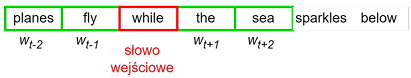

Sieć neuronowa dla skip-gram:
- otrzymuje na wejście słowo w postaci wektora 1 z $n$
- na wyjściu ma funkcję softmax dla $n$ klas
- poprawną wartością wyjściową jest odpowiednie słowo z otoczenia słowa wejściowego


Przewidywanie $w_{t+1}$

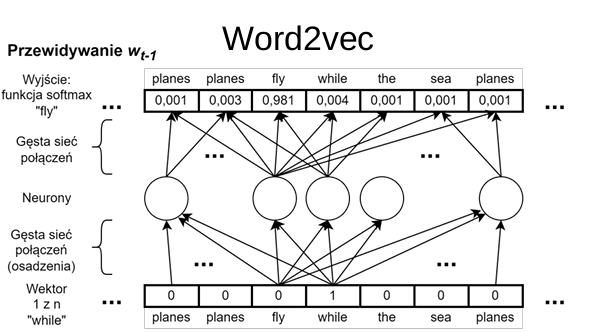

Przewidywanie $w_{t-1}$

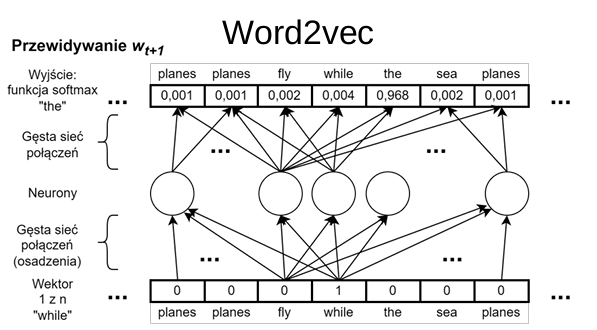

CBoW (Continuous BoW): dla określonej 
(nieparzystej) szerokości okna $L$ na podstawie 
$L − 1$ słów wejściowych przewidywane jest 
otoczone nimi słowo
- Przykład dla $L = 5$

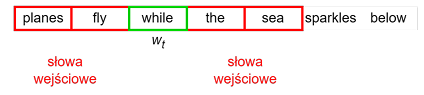

Sieć neuronowa dla CBoW:
- otrzymuje na wejście słowa z otoczenia odgadywanego słowa: wektor wiele z $n$
- na wyjściu ma funkcję softmax dla $n$ klas
- poprawną wartością wyjściową jest odpowiednie 
słowo 

Przewidywanie $w_t$

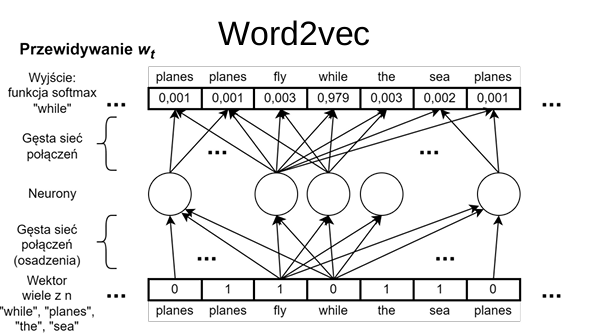

[word2vec-google-news-300](https://drive.google.com/file/d/0B7XkCwpI5KDYNlNUTTlSS21pQmM/edit?resourcekey=0-wjGZdNAUop6WykTtMip30g):
- reprezentacja word2vec trenowana na wiadomościach googla (ok. 100 miliardów słów)
- wektory 300 wymiarowe dla 3 milionów słów
- załadowanie zbioru:

In [36]:
# %pip install gensim

In [37]:
import gensim.downloader

Wytrenowane osadzenia dostępne w `gensim`:

In [38]:
for m in list(gensim.downloader.info()['models'].keys()):
    print(m)

fasttext-wiki-news-subwords-300
conceptnet-numberbatch-17-06-300
word2vec-ruscorpora-300
word2vec-google-news-300
glove-wiki-gigaword-50
glove-wiki-gigaword-100
glove-wiki-gigaword-200
glove-wiki-gigaword-300
glove-twitter-25
glove-twitter-50
glove-twitter-100
glove-twitter-200
__testing_word2vec-matrix-synopsis


Pobranie osadzeń wytrenowanych na wiadomościach googla (dł. wektorów osadzeń wynosi 300):

In [39]:
w2v = gensim.downloader.load('word2vec-google-news-300')

Utworzenie lokalnej kopii pobranych osadzeń:

In [ ]:
w2v.save('word2vec-google-news-300.wordvectors')

Wczytanie lokalnej kopii pobranych osadzeń:

In [44]:
from gensim.models import KeyedVectors

w2v = KeyedVectors.load('word2vec-google-news-300.wordvectors', mmap='r')

10 wyrazów najbliższych w przestrzeni osadzeń do wyrazu `house`:

In [45]:
w2v.most_similar('house')

[('houses', 0.7072390913963318),
 ('bungalow', 0.6878559589385986),
 ('apartment', 0.6628996133804321),
 ('bedroom', 0.6496937274932861),
 ('townhouse', 0.6384080052375793),
 ('residence', 0.6198420524597168),
 ('mansion', 0.6058191657066345),
 ('farmhouse', 0.5857570171356201),
 ('duplex', 0.5757936239242554),
 ('appartment', 0.5690325498580933)]

In [46]:
corpus = ['Birds fly over the sea',
          'People eat food by the sea',
          'Waves crash as birds fly high',
          'Fish is the best food near the sea',
          'Planes fly while the sea sparkles below',
          'Food tastes better with the sea breeze',
          'Birds fly low to find food',
          'The sea is calm while boats bring food',
          'Clouds drift as waves and birds fly',
          'Fresh food is served near the sea'
         ]

Aby wytrenować osadzenia word2vec na naszym mikrokorpusie 10 jednozdaniowych dokumentów, konieczna jest tokenizacja:

In [47]:
from nltk.tokenize import TreebankWordTokenizer

sentences = []
for s in corpus:
    sentences.append(TreebankWordTokenizer().tokenize(s))

Trenowanie osadzeń word2vec o długości 4 na naszym mikrokorpusie:

In [48]:
from gensim.models import Word2Vec

model = Word2Vec(sentences=sentences, vector_size=4, window=5, min_count=1, workers=4)

Ilustracyjne podanie podobnych do "birds" wyrazów, choć nie ma to większego sensu dla tak małego korupsu:

In [49]:
model.wv.most_similar('birds')

[('served', 0.7367929220199585),
 ('with', 0.5528722405433655),
 ('Clouds', 0.4831768572330475),
 ('Food', 0.4607735872268677),
 ('fly', 0.42996665835380554),
 ('Fresh', 0.35824012756347656),
 ('is', 0.30834275484085083),
 ('Waves', 0.23370139300823212),
 ('the', 0.22514455020427704),
 ('calm', 0.1178249940276146)]